<a href="https://colab.research.google.com/github/dinarrahman30/ml_midexam/blob/main/20926006_SK5017_MidExam_Part_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 2: Regression

In [3]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
abalone = fetch_ucirepo(id=1)

# data (as pandas dataframes)
X = abalone.data.features
y = abalone.data.targets

# metadata
print(abalone.metadata)

# variable information
print(abalone.variables)

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Get features and target
features_cols = [col for col in abalone.data.features.columns if col != 'Sex']
X = abalone.data.features[features_cols].copy()

# FIX: Retrieve 'Rings' from targets instead of features
y = abalone.data.targets['Rings']

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features (keeping them as DataFrames to make column selection easy)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

# Select the "Shell_weight" feature and fix spelling typo
x_train_slr = X_train_scaled[["Shell_weight"]]
x_test_slr = X_test_scaled[["Shell_weight"]]

# Model 1: Simple Linear Regression
model_lr = LinearRegression()
model_lr.fit(x_train_slr, y_train)
y_pred_lr = model_lr.predict(x_test_slr)

mse_slr = mean_squared_error(y_test, y_pred_lr)
r2_slr = r2_score(y_test, y_pred_lr)

# Model 2: Multiple Linear Regression
model_mlr = LinearRegression()
model_mlr.fit(X_train_scaled, y_train)
y_pred_mlr = model_mlr.predict(X_test_scaled)

mse_mlr = mean_squared_error(y_test, y_pred_mlr)
r2_mlr = r2_score(y_test, y_pred_mlr)

print("=== Regression Performance Comparison ===")
print(f"Simple Linear Regression (Shell_weight only):")
print(f"  MSE:      {mse_slr:.4f}")
print(f"  RMSE:     {np.sqrt(mse_slr):.4f} rings")
print(f"  R² Score: {r2_slr:.4f}\n")

print(f"Multiple Linear Regression (All features):")
print(f"  MSE:      {mse_mlr:.4f}")
print(f"  RMSE:     {np.sqrt(mse_mlr):.4f} rings")
print(f"  R² Score: {r2_mlr:.4f}")

=== Regression Performance Comparison ===
Simple Linear Regression (Shell_weight only):
  MSE:      6.4859
  RMSE:     2.5467 rings
  R² Score: 0.4009

Multiple Linear Regression (All features):
  MSE:      5.0555
  RMSE:     2.2485 rings
  R² Score: 0.5330


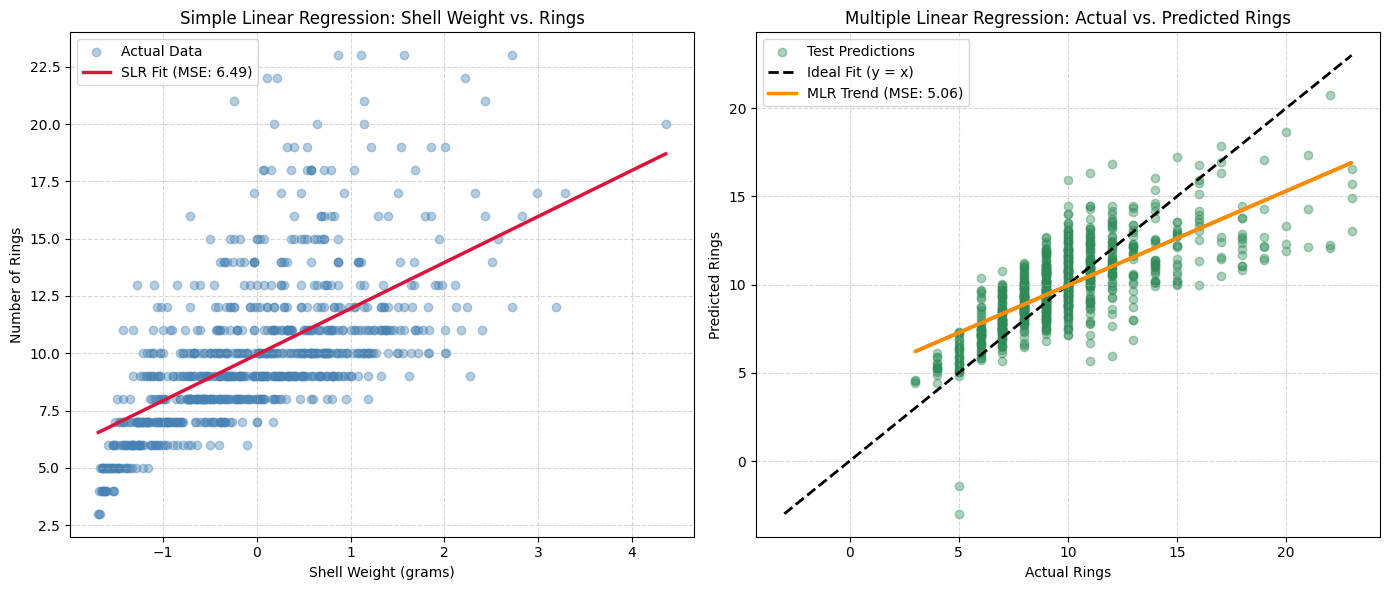

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Simple Linear Regression (Shell_weight vs. Rings)
axes[0].scatter(x_test_slr, y_test, color="steelblue", alpha=0.4, label="Actual Data")
# Sort values for a clean line plot
sorted_idx = np.argsort(x_test_slr.values.flatten())
axes[0].plot(
    x_test_slr.values.flatten()[sorted_idx],
    y_pred_lr[sorted_idx],
    color="crimson",
    linewidth=2.5,
    label=f"SLR Fit (MSE: {mse_slr:.2f})"
)
axes[0].set_title("Simple Linear Regression: Shell Weight vs. Rings")
axes[0].set_xlabel("Shell Weight (grams)")
axes[0].set_ylabel("Number of Rings")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Multiple Linear Regression (Actual vs. Predicted Rings)
axes[1].scatter(y_test, y_pred_mlr, color="seagreen", alpha=0.4, label="Test Predictions")
# Ideal 1:1 Reference Line + Fitted Trend Line
min_val, max_val = min(y_test.min(), y_pred_mlr.min()), max(y_test.max(), y_pred_mlr.max())
axes[1].plot([min_val, max_val], [min_val, max_val], color="black", linestyle="--", linewidth=2, label="Ideal Fit (y = x)")
# Best-fit line through Actual vs Predicted
m, b = np.polyfit(y_test, y_pred_mlr, 1)
axes[1].plot(y_test, m * y_test + b, color="darkorange", linewidth=2.5, label=f"MLR Trend (MSE: {mse_mlr:.2f})")

axes[1].set_title("Multiple Linear Regression: Actual vs. Predicted Rings")
axes[1].set_xlabel("Actual Rings")
axes[1].set_ylabel("Predicted Rings")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Part 2: Regression Model Comparison & Analysis

### 1. Model Performance Summary
Using physical dimensions of the abalone to predict the number of rings (which represents age), we trained and compared two regression models on the dataset:

*   **Simple Linear Regression (SLR)** using only the single strongest predictor, `Shell_weight`:
    *   **Mean Squared Error (MSE):** `6.4859`
    *   **Root Mean Squared Error (RMSE):** `2.5467` rings
    *   **R² Score:** `0.4009` (explains approximately 40.1% of the variance in rings)

*   **Multiple Linear Regression (MLR)** using all continuous physical features (`Length`, `Diameter`, `Height`, `Whole_weight`, `Shucked_weight`, `Viscera_weight`, `Shell_weight`):
    *   **Mean Squared Error (MSE):** `5.0555`
    *   **Root Mean Squared Error (RMSE):** `2.2485` rings
    *   **R² Score:** `0.5330` (explains approximately 53.3% of the variance in rings)

---

### 2. Which Model Performed Better?
**Multiple Linear Regression** performed significantly better than Simple Linear Regression.
*   It achieved a lower Mean Squared Error (**5.0555** compared to **6.4859**).
*   It raised the R² score from **0.4009** to **0.5330**, proving that combining multiple anatomical metrics yields a much more robust predictor than focusing on any single weight metric alone.

---

### 3. Strengths and Weaknesses of the Algorithms on this Dataset

#### A. Simple Linear Regression (Shell Weight only)
*   **Strengths:**
    *   **Highly Interpretable:** The model represents a basic linear baseline: a direct relationship indicating that dried shell weight increases predictably as the abalone grows older and adds more rings.
    *   **Simplicity:** Very low risk of overfitting; requires minimal computational resources.
*   **Weaknesses:**
    *   **High Bias (Underfitting):** By ignoring size measurements (Length, Height) and wet weight proportions (Shucked weight, Viscera weight), it fails to capture the multi-dimensional growth pattern of abalones, leaving ~60% of the variance unexplained.

#### B. Multiple Linear Regression (All features)
*   **Strengths:**
    *   **Comprehensive Coverage:** By incorporating body volume features (`Length`, `Diameter`, `Height`) along with the differences in meat versus shell weight, the model gains crucial context about individual growth patterns and body density.
    *   **Better Fit:** Substantially reduces prediction error across the test split.
*   **Weaknesses:**
    *   **Multicollinearity:** The continuous features (various weight measurements and physical dimensions) are extremely highly correlated with each other. This collinearity can destabilize the model's coefficients, making individual feature importances hard to interpret reliably.
    *   **Assumption of Linearity:** Abalone growth rate naturally slows down as they reach maturity, meaning the true relationship between physical dimensions and age is non-linear. Linear models cannot fit this plateau curve well, which explains why the multiple regression R² score caps around `0.53`.